In [1]:
from datasets import load_dataset
import nltk
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


/Users/ninahew/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/ninahew/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [2]:
# Write a function that takes an integer x and two languages, and returns shared word analysis across x number of wikipedia articles

def analyse_lang(x, lang):
    lang_ds = load_dataset("wikimedia/wikipedia", "20231101.{lang}".format(lang=lang))
    print('dataset ' + '{lang}'.format(lang=lang) + ' loaded')
    corpus_lang = lang_ds['train']['text'][0:x]
    # print(corpus_lang)
    # Convert to big string
    string_lang = " ".join(corpus_lang)
    tokenized_lang= word_tokenize(string_lang)
    # print("{lang}".format(lang=lang) + " after tokenisation")
    # print("{lang}".format(lang=lang), " : ", str(len(tokenized_lang)), " words")
    # Remove punctuation, proper nouns and numerical entries
    cleaned_lang = [word for word in tokenized_lang if ((len(word) > 2) and (not(word[0].isupper())) and (not(word.isnumeric())))]
    # print("{lang}".format(lang=lang) + " after data cleaning")
    # print("{lang}".format(lang=lang), " : ", str(len(cleaned_lang)), " words")
    dict_lang = {}
    for word in cleaned_lang:
        if word not in dict_lang:
            dict_lang[word] = 0
        dict_lang[word] += 1
    return dict_lang


# Generate Shared word analysis
def shared_word_analysis(x,lang_1, lang_2):
    lang_1_analysed = analyse_lang(x,lang_1)
    lang_2_analysed = analyse_lang(x,lang_2)
    lang_1_col_name = 'word_freq_{lang_1}'.format(lang_1=lang_1)
    lang_1_df = pd.DataFrame.from_dict(lang_1_analysed, orient='index', columns=[lang_1_col_name])
    print(lang_1_df.sort_values(by = ['word_freq_{lang_1}'.format(lang_1=lang_1)], ascending= False).head(20))
    lang_2_col_name = 'word_freq_{lang_2}'.format(lang_2=lang_2)
    lang_2_df = pd.DataFrame.from_dict(lang_2_analysed, orient='index', columns = [lang_2_col_name])
    print(lang_2_df.sort_values(by = ['word_freq_{lang_2}'.format(lang_2=lang_2)], ascending= False).head(20))
    shared_words = pd.merge(lang_1_df, lang_2_df, how = 'inner', left_index=True, right_index=True)
    print(str(shared_words.size), " words shared between both languages")
    sns.set_theme(rc={'figure.figsize':(16,6)})
    sns.set_theme(style="darkgrid", context="paper")
    sns.color_palette("Spectral", as_cmap=True)
    # print(shared_words)
    # print(type(shared_words))
    shared_words_top_100 = shared_words.nlargest(100, columns = [lang_1_col_name, lang_2_col_name])
    # print('Top 100 most shared words')
    shared_100_plot = sns.lineplot(data = shared_words_top_100, sort = True)
    shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)
    return shared_100_plot



dataset af loaded
dataset nl loaded
          word_freq_af
die            292    
van            107    
wat             42    
het             30    
word            27    
nie             25    
deur            20    
baie            19    
dit             18    
met             15    
groot           15    
tot             14    
grootste        13    
daar            13    
vir             13    
kan             12    
deel            12    
ook             12    
aan             11    
jaar            11    
      word_freq_nl
van        152    
het         79    
een         75    
zijn        45    
hij         34    
voor        31    
met         30    
was         30    
werd        25    
als         25    
aan         23    
die         22    
dat         21    
door        19    
niet        16    
uit         13    
tot         12    
had         12    
over        11    
deze        10    
158  words shared between both languages


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_6158/3985180214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


<Axes: >

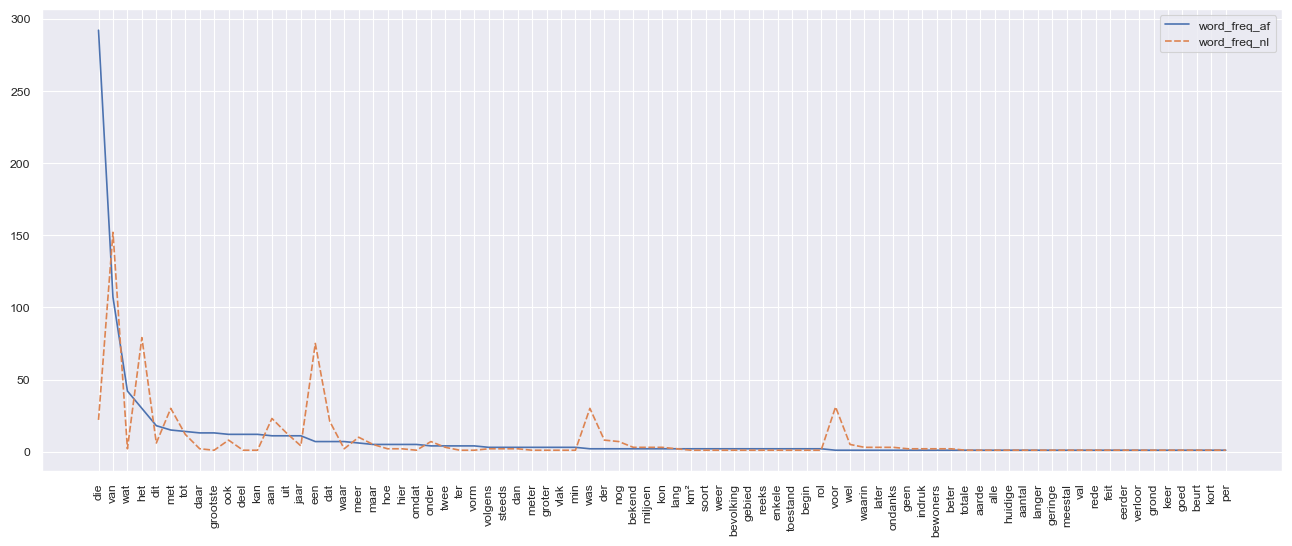

In [4]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.colheader_justify', 'center')
pd.set_option('display.precision', 2)
# display(df)

# Shared words across 1 wikipedia article each
shared_word_analysis(1,'af','nl')

dataset nl loaded
dataset af loaded
      word_freq_nl
van        152    
het         79    
een         75    
zijn        45    
hij         34    
voor        31    
met         30    
was         30    
werd        25    
als         25    
aan         23    
die         22    
dat         21    
door        19    
niet        16    
uit         13    
tot         12    
had         12    
over        11    
deze        10    
          word_freq_af
die            292    
van            107    
wat             42    
het             30    
word            27    
nie             25    
deur            20    
baie            19    
dit             18    
met             15    
groot           15    
tot             14    
grootste        13    
daar            13    
vir             13    
kan             12    
deel            12    
ook             12    
aan             11    
jaar            11    
158  words shared between both languages


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_6158/3985180214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


<Axes: >

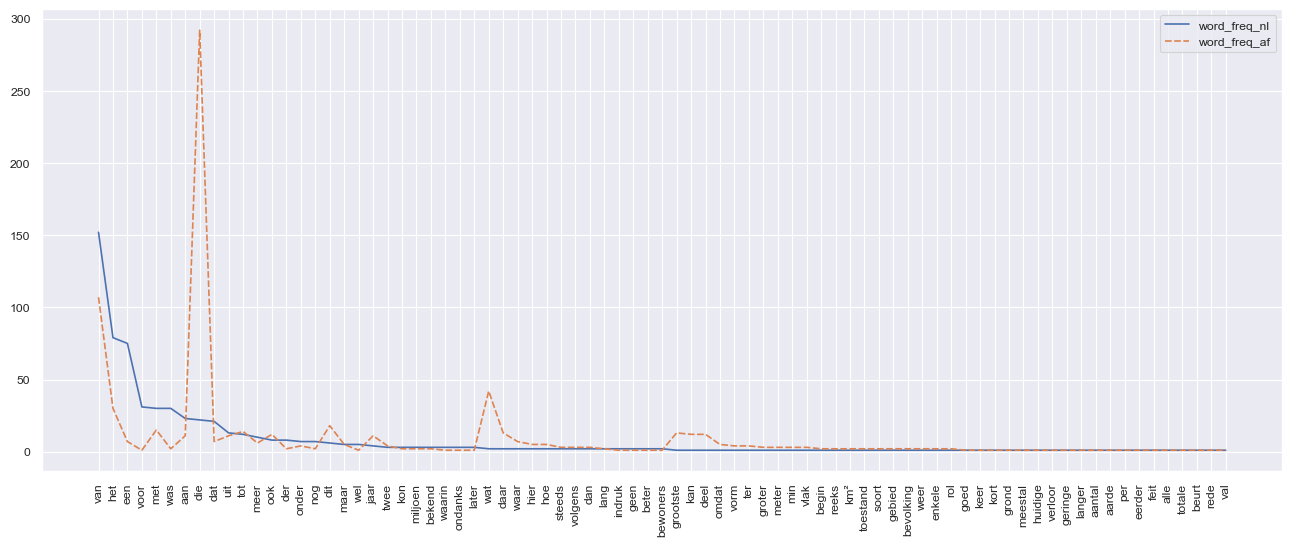

In [5]:
# Shared words across 1 wikipedia article each, other way around
shared_word_analysis(1,'nl','af')

dataset af loaded
dataset nl loaded
       word_freq_af
die        17870   
van         8768   
het         4150   
wat         2652   
word        2061   
met         1865   
deur        1375   
vir         1373   
nie         1164   
ook         1064   
was         1036   
aan         1017   
tot          930   
dat          723   
uit          692   
soos         655   
dit          644   
oor          588   
ander        556   
hulle        547   
        word_freq_nl
van         7101    
het         4810    
een         4088    
zijn        1932    
met         1492    
voor        1309    
die         1302    
door        1143    
dat         1055    
als         1045    
aan          978    
werd         971    
was          829    
tot          762    
uit          754    
ook          725    
hij          696    
worden       695    
wordt        662    
niet         620    
4856  words shared between both languages


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_6158/3985180214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


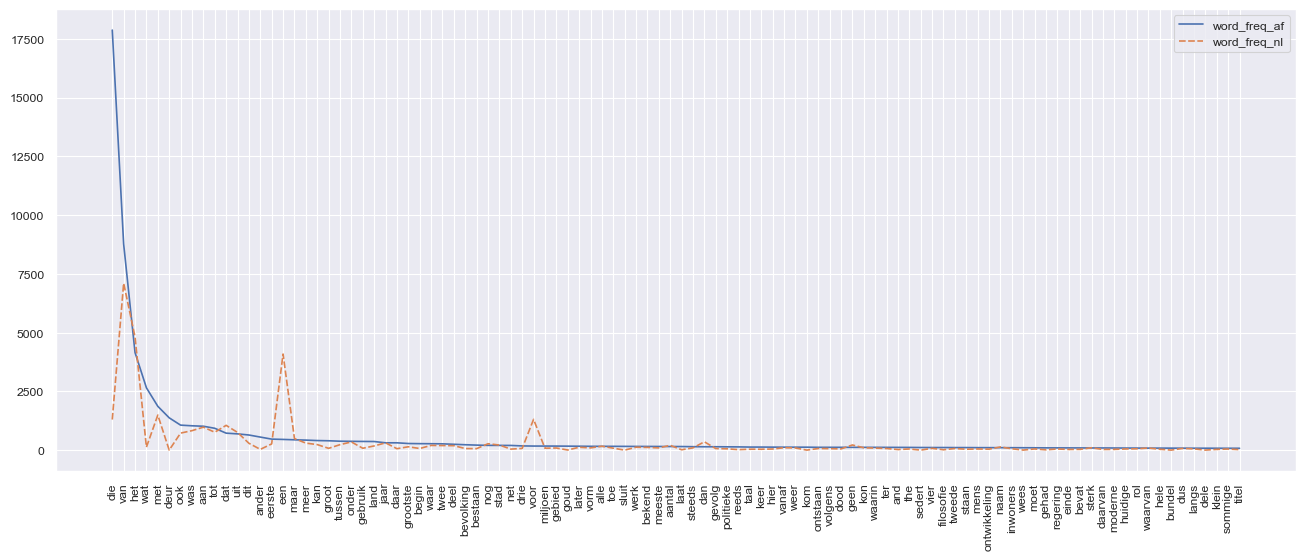

In [6]:
# Shared words across 100 Wikipedia articles

print(shared_word_analysis(100, 'af','nl'))

dataset nl loaded
dataset af loaded
        word_freq_nl
van         7101    
het         4810    
een         4088    
zijn        1932    
met         1492    
voor        1309    
die         1302    
door        1143    
dat         1055    
als         1045    
aan          978    
werd         971    
was          829    
tot          762    
uit          754    
ook          725    
hij          696    
worden       695    
wordt        662    
niet         620    
       word_freq_af
die        17870   
van         8768   
het         4150   
wat         2652   
word        2061   
met         1865   
deur        1375   
vir         1373   
nie         1164   
ook         1064   
was         1036   
aan         1017   
tot          930   
dat          723   
uit          692   
soos         655   
dit          644   
oor          588   
ander        556   
hulle        547   
4856  words shared between both languages
Axes(0.125,0.11;0.775x0.77)


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_6158/3985180214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


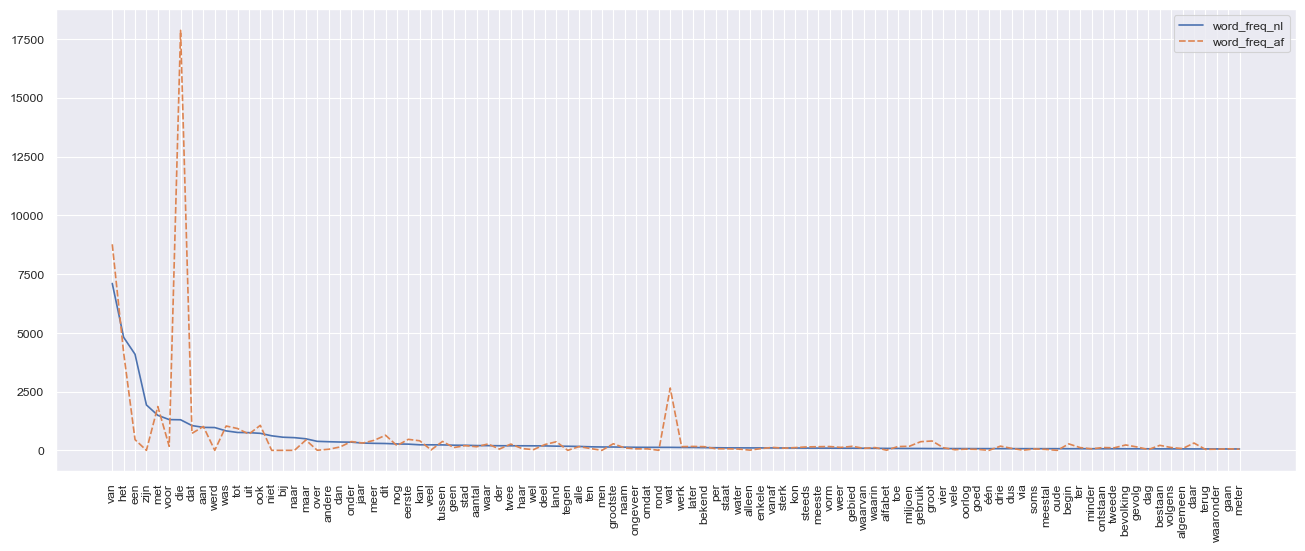

In [7]:
# Shared words across 100 Wikipedia articles, other way around

print(shared_word_analysis(100, 'nl','af'))

dataset af loaded
dataset nl loaded
         word_freq_af
die          42367   
van          24462   
het           9078   
word          5905   
wat           5672   
met           3623   
jaar          3283   
was           3265   
deur          2997   
vir           2815   
aan           2663   
nie           2073   
tot           1902   
eeu           1800   
ook           1794   
eerste        1739   
ander         1452   
begin         1370   
skrywer       1355   
uit           1345   
        word_freq_nl
van         65852   
het         43225   
een         36257   
zijn        16119   
met         14170   
die         11798   
voor        11720   
door         9962   
dat          9832   
als          9339   
werd         9073   
aan          8644   
was          8232   
ook          6926   
tot          6730   
uit          6398   
hij          6173   
worden       5510   
niet         5492   
wordt        5439   
11748  words shared between both languages


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_6158/3985180214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


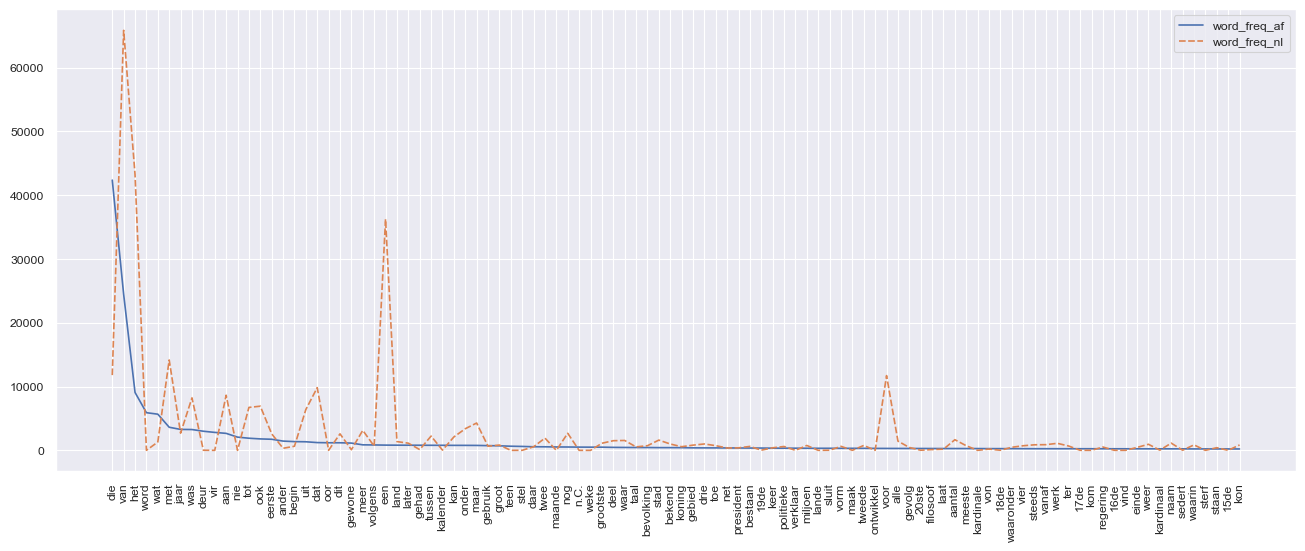

In [8]:
# Shared words across 1000 Wikipedia articles

print(shared_word_analysis(1000, 'af','nl'))

dataset nl loaded
dataset af loaded
        word_freq_nl
van         65852   
het         43225   
een         36257   
zijn        16119   
met         14170   
die         11798   
voor        11720   
door         9962   
dat          9832   
als          9339   
werd         9073   
aan          8644   
was          8232   
ook          6926   
tot          6730   
uit          6398   
hij          6173   
worden       5510   
niet         5492   
wordt        5439   
         word_freq_af
die          42367   
van          24462   
het           9078   
word          5905   
wat           5672   
met           3623   
jaar          3283   
was           3265   
deur          2997   
vir           2815   
aan           2663   
nie           2073   
tot           1902   
eeu           1800   
ook           1794   
eerste        1739   
ander         1452   
begin         1370   
skrywer       1355   
uit           1345   
11748  words shared between both languages


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_6158/3985180214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


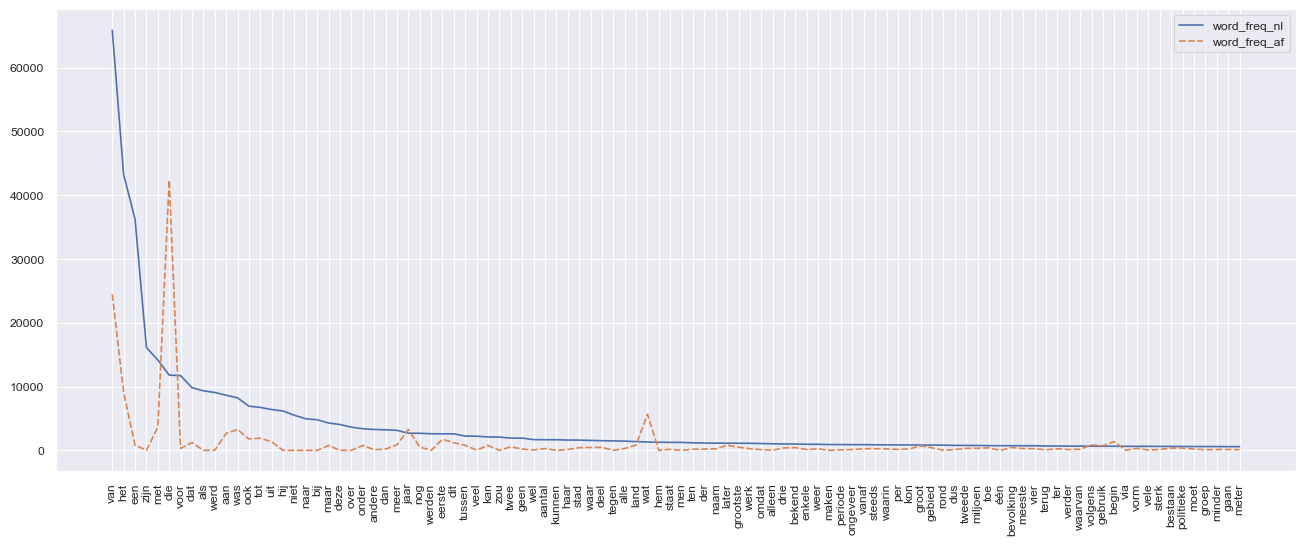

In [9]:
# Shared words across 1000 Wikipedia articles, other way around

print(shared_word_analysis(1000, 'nl','af'))

dataset af loaded
dataset nl loaded
        word_freq_af
die        469740   
van        229829   
het        120894   
wat         65676   
word        57888   
met         48178   
was         36827   
deur        35494   
vir         34757   
nie         34335   
aan         27737   
ook         25341   
tot         23235   
dit         18754   
dat         18626   
jaar        17326   
hulle       17126   
uit         16027   
kan         13341   
eerste      12980   
           word_freq_nl
van           467930   
het           282297   
een           255114   
zijn          101477   
met            96969   
voor           78652   
die            74006   
door           69472   
dat            64951   
als            62254   
aan            57633   
werd           53899   
wordt          53739   
was            47449   
tot            45146   
ook            44176   
overleden      43730   
uit            43555   
worden         40912   
bij            38388   
60054  words shared

/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_6158/3985180214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


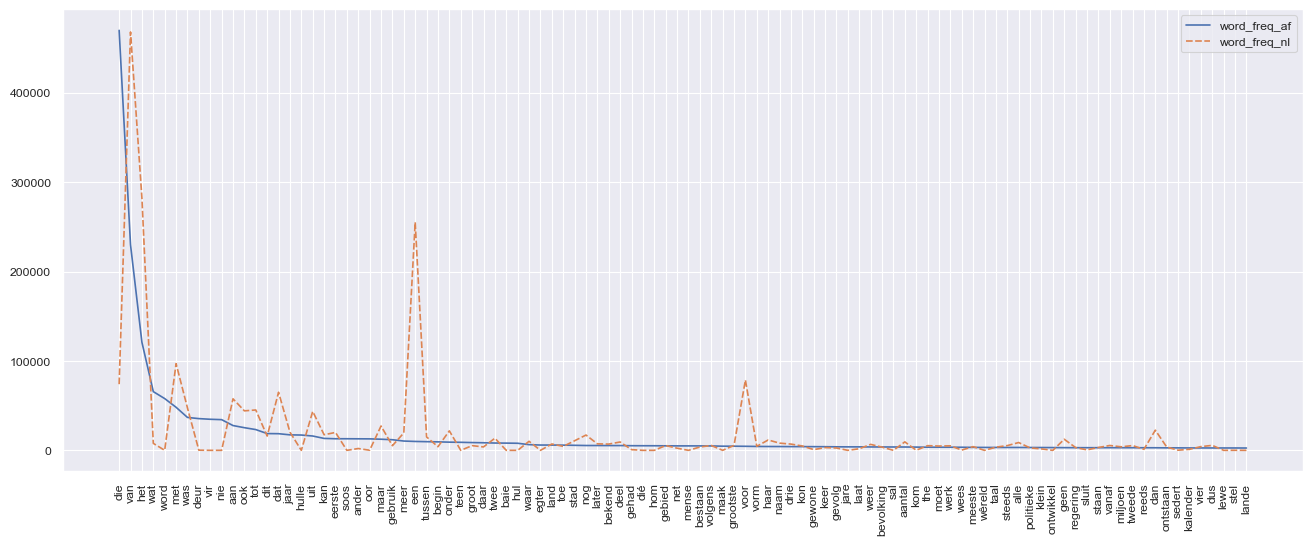

In [10]:
# Shared words across 10000 Wikipedia articles

print(shared_word_analysis(10000, 'af','nl'))

dataset nl loaded
dataset af loaded
           word_freq_nl
van           467930   
het           282297   
een           255114   
zijn          101477   
met            96969   
voor           78652   
die            74006   
door           69472   
dat            64951   
als            62254   
aan            57633   
werd           53899   
wordt          53739   
was            47449   
tot            45146   
ook            44176   
overleden      43730   
uit            43555   
worden         40912   
bij            38388   
        word_freq_af
die        469740   
van        229829   
het        120894   
wat         65676   
word        57888   
met         48178   
was         36827   
deur        35494   
vir         34757   
nie         34335   
aan         27737   
ook         25341   
tot         23235   
dit         18754   
dat         18626   
jaar        17326   
hulle       17126   
uit         16027   
kan         13341   
eerste      12980   
60054  words shared

/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_6158/3985180214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


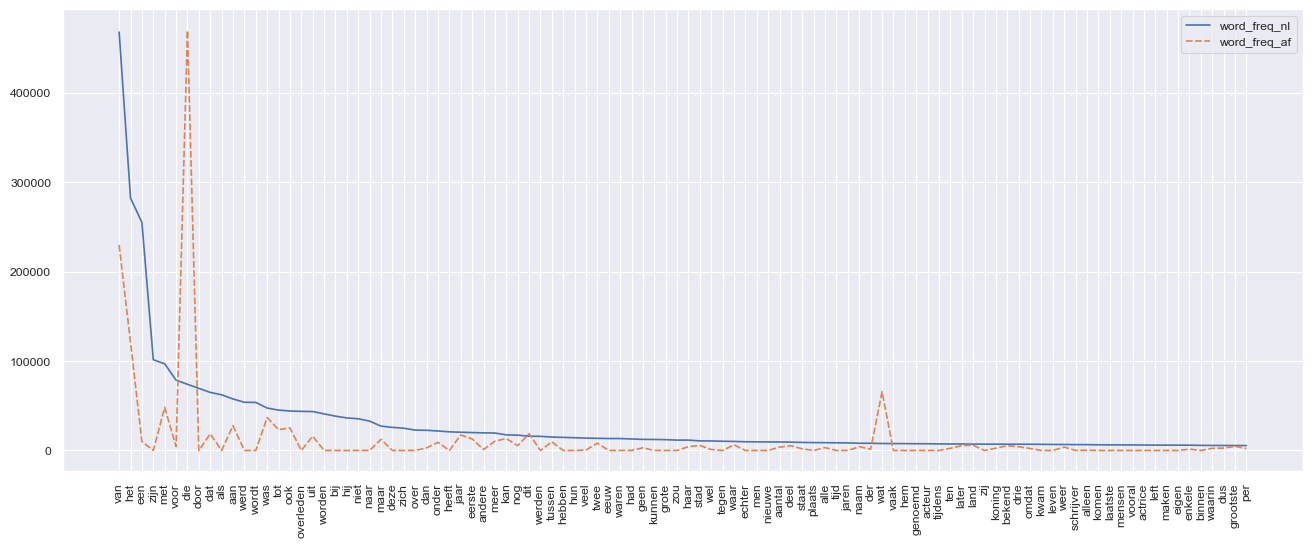

In [11]:
# Shared words across 10000 Wikipedia articles, other way around

print(shared_word_analysis(10000, 'nl','af'))

TESTING NL AND VLS

dataset vls loaded
dataset nl loaded
        word_freq_vls
van          141     
den           33     
zyn           28     
die           28     
een           20     
stad          18     
nog           18     
met           18     
noa           16     
uut           16     
ôok           15     
der           14     
dat           13     
lik           12     
wordt         10     
deur          10     
over           9     
gekend         8     
moa            8     
andere         8     
        word_freq_nl
van         1065    
het          705    
een          512    
zijn         245    
met          219    
werd         168    
voor         166    
die          157    
door         145    
aan          141    
als          122    
tot          119    
dat          118    
ook          107    
hij          103    
uit           97    
was           94    
naar          87    
wordt         81    
worden        78    
346  words shared between both languages


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_6158/3985180214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


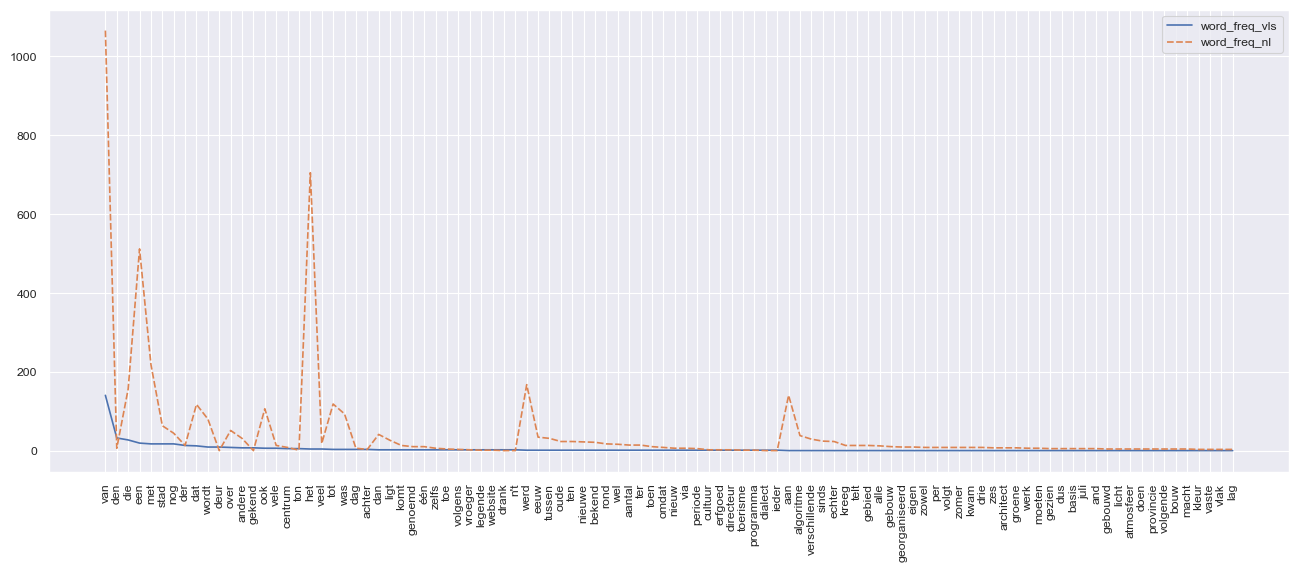

In [12]:
# Shared words across 10 Wikipedia articles

print(shared_word_analysis(10, 'vls','nl'))


dataset nl loaded
dataset vls loaded
        word_freq_nl
van         1065    
het          705    
een          512    
zijn         245    
met          219    
werd         168    
voor         166    
die          157    
door         145    
aan          141    
als          122    
tot          119    
dat          118    
ook          107    
hij          103    
uit           97    
was           94    
naar          87    
wordt         81    
worden        78    
        word_freq_vls
van          141     
den           33     
zyn           28     
die           28     
een           20     
stad          18     
nog           18     
met           18     
noa           16     
uut           16     
ôok           15     
der           14     
dat           13     
lik           12     
wordt         10     
deur          10     
over           9     
gekend         8     
moa            8     
andere         8     
346  words shared between both languages
Axes(0.125,0.11;0.7

/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_6158/3985180214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


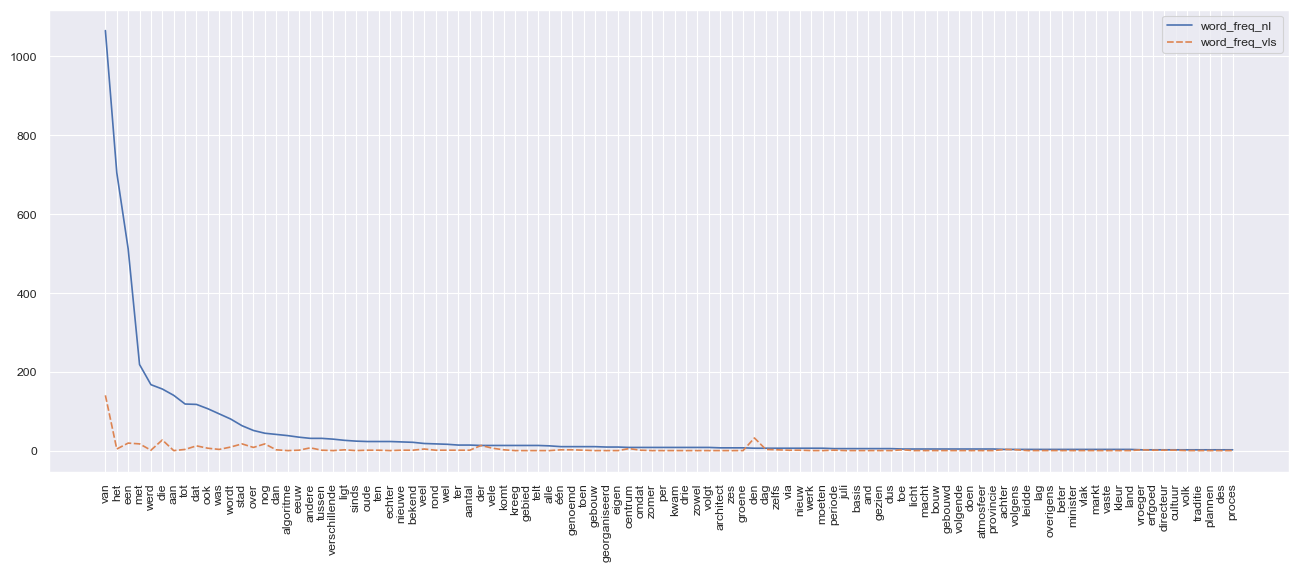

In [13]:
# Shared words across 10 Wikipedia articles, other way around

print(shared_word_analysis(10,'nl', 'vls'))


dataset vls loaded
dataset nl loaded
          word_freq_vls
van           1023     
zyn            274     
een            214     
die            195     
den            154     
met            127     
dat            117     
nog            112     
deur           100     
der             95     
wos             88     
noa             87     
ôok             87     
uut             83     
nie             79     
voe             68     
ook             67     
gemêente        65     
stad            60     
moa             59     
        word_freq_nl
van         7101    
het         4810    
een         4088    
zijn        1932    
met         1492    
voor        1309    
die         1302    
door        1143    
dat         1055    
als         1045    
aan          978    
werd         971    
was          829    
tot          762    
uit          754    
ook          725    
hij          696    
worden       695    
wordt        662    
niet         620    
2458  words shared

/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_6158/3985180214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


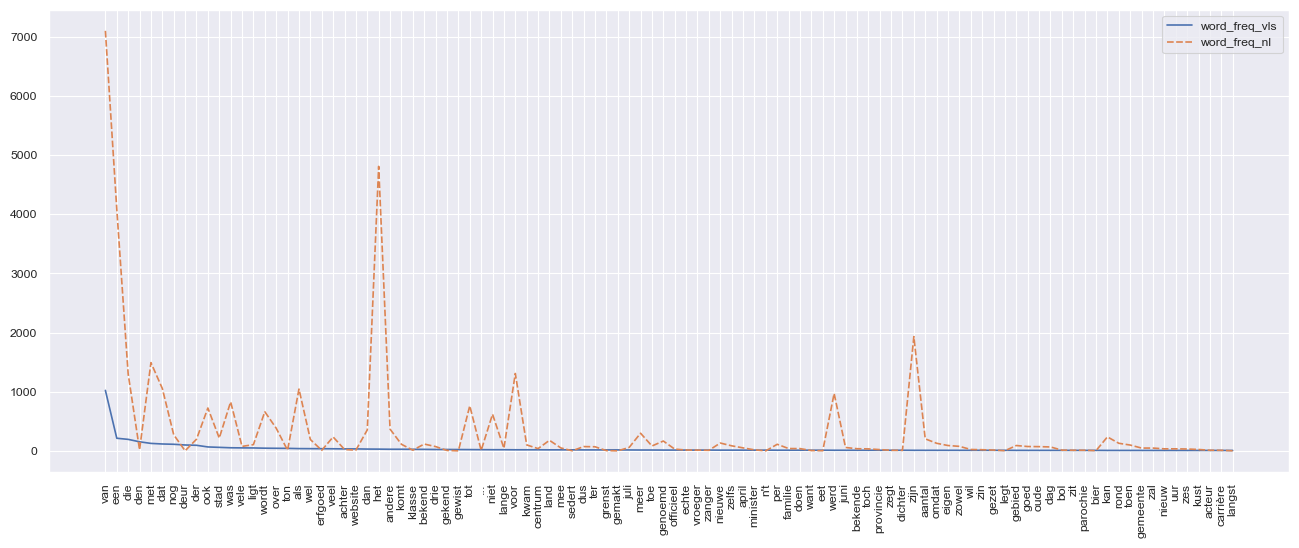

In [14]:
# Shared words across 100 Wikipedia articles

print(shared_word_analysis(100, 'vls','nl'))


dataset nl loaded
dataset vls loaded
        word_freq_nl
van         7101    
het         4810    
een         4088    
zijn        1932    
met         1492    
voor        1309    
die         1302    
door        1143    
dat         1055    
als         1045    
aan          978    
werd         971    
was          829    
tot          762    
uit          754    
ook          725    
hij          696    
worden       695    
wordt        662    
niet         620    
          word_freq_vls
van           1023     
zyn            274     
een            214     
die            195     
den            154     
met            127     
dat            117     
nog            112     
deur           100     
der             95     
wos             88     
noa             87     
ôok             87     
uut             83     
nie             79     
voe             68     
ook             67     
gemêente        65     
stad            60     
moa             59     
2458  words shared

/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_6158/3985180214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


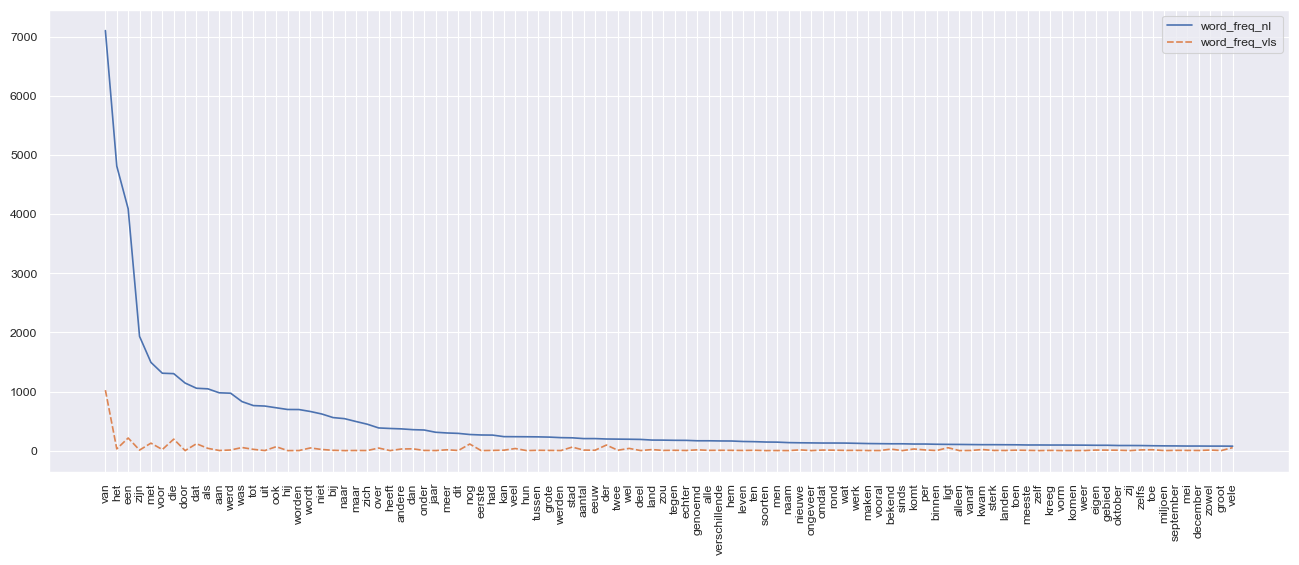

In [15]:
# Shared words across 100 Wikipedia articles, other way around

print(shared_word_analysis(100, 'nl','vls'))
